# ConSurf Cross-Validation (one-off)

Independent check of the MMseqs2 -> MAFFT -> weighted Shannon entropy conservation pipeline (`03_conservation_analysis.py`) against ConSurf's own output for the same protein.

**Not part of the numbered workflow** -- ConSurf was replaced precisely because it's unreliable to run programmatically. This is a methodological validation done once, not a step future targets need.

### Two things to keep in mind when reading the results

1. **The score scales are inverted relative to each other.** ConSurf's normalized score runs ~-1.192 (most conserved) to ~+2.900 (most variable); Shannon entropy runs low (conserved) to high (variable). So `consurf_score` vs `cons_shannon_entropy` should correlate **positively**. Both *grade* scales use 9 = most conserved, so grades should also correlate positively.

2. **These are two different alignments, not one alignment scored twice.** ConSurf's MSA here is far shallower (position 1 percentages imply ~13 sequences; position 2 ~23) than the MMseqs2/UniRef90 run (~550 sequences at comparable positions). Disagreement is therefore expected and is not by itself evidence either method is wrong. Results are stratified by ConSurf's own insufficient-data marker below.

In [1]:
import re
import sys
sys.path.append("../workflow")

from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr

from project_utils import resolve_path

pd.set_option("display.max_columns", 60)

cfg = yaml.safe_load(resolve_path("config.yaml").read_text())
results_dir = resolve_path(cfg["paths"]["results_dir"])

# ConSurf archive contents (stored under results/, per project convention)
CONSURF_DIR = results_dir / "consurf"

out_dir = results_dir / "validation_consurf"
fig_dir = out_dir / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

grades_file = CONSURF_DIR / "P07254_consurf_grades.txt"
variety_file = CONSURF_DIR / "msa_aa_variety_percentage.csv"

for f in (grades_file, variety_file):
    print(f"{'OK  ' if f.exists() else 'MISSING'} {f}")

OK   N:\Jupiter_Projects\rational-enzyme-engineering\results\consurf\P07254_consurf_grades.txt
OK   N:\Jupiter_Projects\rational-enzyme-engineering\results\consurf\msa_aa_variety_percentage.csv


## Parse ConSurf grades

The file has a prose header of unknown length, then a fixed-ish-width table. Rather than hardcode a skiprows count (fragile across ConSurf versions), locate the header row by content and parse data rows by regex, logging anything unparsed instead of dropping it silently.

In [2]:
raw_lines = grades_file.read_text(errors="replace").splitlines()

# Find the column-header line (contains POS, SEQ, SCORE)
header_idx = None
for i, line in enumerate(raw_lines):
    if re.search(r"\bPOS\b", line) and re.search(r"\bSEQ\b", line) and re.search(r"\bSCORE\b", line):
        header_idx = i
        break

if header_idx is None:
    raise RuntimeError("Could not locate the column-header line in the ConSurf grades file. "
                        "Print raw_lines[:40] and inspect manually.")

print(f"Header line at index {header_idx}:")
print(repr(raw_lines[header_idx]))
print("\nNext 5 lines:")
for line in raw_lines[header_idx + 1: header_idx + 6]:
    print(repr(line))

Header line at index 27:
'POS\tSEQ\t     ATOM\t SCORE\tCOLOR\tCONFIDENCE INTERVAL\tB/E\tF/S\tMSA DATA\tRESIDUE VARIETY'

Next 5 lines:
''
'  1\t  M\t  MET:1:A\t 0.207\t   5 \t-0.275,  0.594  6,4\t  e\t   \t  13/150\tM 53%, I 15%, H  7%, R  7%, L  7%, F  7%'
'  2\t  R\t  ARG:2:A\t 0.667\t   4 \t 0.121,  1.139  5,3\t  e\t   \t  23/150\tK 56%, R 13%, A  8%, S  4%, C  4%, M  4%, N  4%, I  4%'
'  3\t  K\t  LYS:3:A\t 0.129\t   5 \t-0.423,  0.406  7,4\t  e\t   \t  19/150\tF 47%, K 26%, R 15%, L 10%'
'  4\t  F\t  PHE:4:A\t 0.545\t   4 \t 0.004,  0.827  5,4\t  e\t   \t  25/150\tM 48%, F 28%, L 16%, Y  4%, G  4%'


In [3]:
# The file is tab-separated with a known header (confirmed by inspection above):
#   POS  SEQ  ATOM  SCORE  COLOR  CONFIDENCE INTERVAL  B/E  F/S  MSA DATA  RESIDUE VARIETY
# Parse by column, not by regex -- an earlier regex approach silently picked up
# digits from the ATOM field (e.g. 'MET:1:A') instead of the COLOR/grade column,
# producing a plausible-looking but entirely wrong grade series.
EXPECTED_COLS = ["POS", "SEQ", "ATOM", "SCORE", "COLOR", "CONFIDENCE INTERVAL",
                 "B/E", "F/S", "MSA DATA", "RESIDUE VARIETY"]

header_cols = [c.strip() for c in raw_lines[header_idx].split("\t")]
print(f"Header columns found: {header_cols}")
assert header_cols[:5] == EXPECTED_COLS[:5], (
    f"Unexpected ConSurf column layout: {header_cols}. "
    f"Inspect the file before trusting this parse.")

records, unparsed = [], []
for line in raw_lines[header_idx + 1:]:
    if not line.strip():
        continue
    fields = [f.strip() for f in line.split("\t")]
    if len(fields) < 5 or not fields[0].isdigit():
        unparsed.append(line)   # prose footnotes at end of file land here
        continue

    color_field = fields[4]                      # e.g. '5' or '5*'
    grade_digits = color_field.replace("*", "").strip()
    msa_field = fields[8] if len(fields) > 8 else ""   # e.g. '13/150'
    variety_field = fields[9] if len(fields) > 9 else ""

    n_seqs = np.nan
    if "/" in msa_field:
        try:
            n_seqs = int(msa_field.split("/")[0].strip())
        except ValueError:
            pass

    records.append({
        "residue_number": int(fields[0]),
        "consurf_seq": fields[1],
        "consurf_atom": fields[2],
        "consurf_score": float(fields[3]),
        "consurf_grade": int(grade_digits) if grade_digits.isdigit() else np.nan,
        "consurf_insufficient_data": "*" in color_field,
        "consurf_n_sequences": n_seqs,
        "consurf_burial": fields[6] if len(fields) > 6 else "",
        "consurf_variety": variety_field,
    })

consurf_df = pd.DataFrame(records)
print(f"\nParsed {len(consurf_df)} rows; {len(unparsed)} unparsed (trailing prose footnotes are expected here).")
if unparsed:
    for line in unparsed[:3]:
        print(f"   skipped: {line[:90]}")

print(f"\nInsufficient-data positions: {consurf_df['consurf_insufficient_data'].sum()}")
print(f"ConSurf MSA depth: median {consurf_df['consurf_n_sequences'].median():.0f}, "
      f"range {consurf_df['consurf_n_sequences'].min():.0f}-{consurf_df['consurf_n_sequences'].max():.0f} sequences")
consurf_df.head(10)

Header columns found: ['POS', 'SEQ', 'ATOM', 'SCORE', 'COLOR', 'CONFIDENCE INTERVAL', 'B/E', 'F/S', 'MSA DATA', 'RESIDUE VARIETY']

Parsed 563 rows; 2 unparsed (trailing prose footnotes are expected here).
   skipped: *Below the confidence cut-off - The calculations for this site were performed on less than
   skipped: or the confidence interval for the estimated score is equal to- or larger than- 4 color gr

Insufficient-data positions: 1
ConSurf MSA depth: median 149, range 4-150 sequences


,residue_number,consurf_seq,consurf_atom,consurf_score,consurf_grade,consurf_insufficient_data,consurf_n_sequences,consurf_burial,consurf_variety
0,1,M,MET:1:A,0.207,5,False,13,e,"M 53%, I 15%, H 7%, R 7%, L 7%, F 7%"
1,2,R,ARG:2:A,0.667,4,False,23,e,"K 56%, R 13%, A 8%, S 4%, C 4%, M 4%, N 4..."
2,3,K,LYS:3:A,0.129,5,False,19,e,"F 47%, K 26%, R 15%, L 10%"
3,4,F,PHE:4:A,0.545,4,False,25,e,"M 48%, F 28%, L 16%, Y 4%, G 4%"
4,5,N,ASN:5:A,0.415,4,False,30,e,"K 53%, N 20%, L 6%, R 6%, G 3%, S 3%, T 3..."
5,6,K,LYS:6:A,0.905,4,False,38,e,"K 36%, P 31%, R 10%, L 5%, Q 5%, F 5%, I 2..."
6,7,P,PRO:7:A,2.395,1,False,50,e,"K 26%, S 20%, T 16%, P 8%, L 8%, N 8%, Q 6..."
7,8,L,LEU:8:A,1.913,2,False,63,b,"L 38%, Y 17%, M 11%, I 11%, V 7%, H 3%, F 3..."
8,9,L,LEU:9:A,1.504,3,False,74,b,"L 66%, T 8%, I 8%, A 5%, S 4%, C 4%, V 2..."
9,10,A,ALA:10:A,0.008,5,False,84,b,"A 70%, S 7%, L 7%, T 5%, P 2%, F 2%, K 1..."


### Sanity-check the parse before trusting it

Grades must map monotonically onto score bands (per the file's own header: grade 9 = most negative score, grade 1 = most positive). If this plot isn't monotonic, the regex grabbed the wrong field.

In [4]:
band_check = consurf_df.groupby("consurf_grade")["consurf_score"].agg(["min", "max", "count"])
display(band_check)

is_monotonic = band_check["min"].is_monotonic_decreasing or band_check["max"].is_monotonic_decreasing
print(f"Grade->score bands monotonic (expected True): {is_monotonic}")
if not is_monotonic:
    print("*** Parse is suspect -- inspect the raw lines before using these values. ***")

,min,max,count
consurf_grade,,,
1,2.395,2.900,19
2,1.625,2.248,27
3,0.971,1.590,52
4,0.344,0.961,75
5,-0.126,0.317,99
6,-0.397,-0.140,49
7,-0.662,-0.407,66
8,-0.926,-0.663,62
9,-1.192,-0.929,114


Grade->score bands monotonic (expected True): True


## Join against the pipeline's conservation table

ConSurf ran on the UniProt query sequence (numbering 1-563), matching `03`'s numbering directly -- no offset needed. Its `SEQ` letter should match `wt_residue_uniprot`, including at the 6 known UniProt-vs-structure conflict positions.

In [5]:
cons_df = pd.read_csv(results_dir / "03_conservation" / "conservation_scores.csv")

comp = cons_df.merge(consurf_df, on="residue_number", how="inner")
print(f"Joined on {len(comp)} shared positions "
      f"(pipeline: {len(cons_df)}, ConSurf: {len(consurf_df)}).")

seq_mismatch = comp[comp["wt_residue"] != comp["consurf_seq"]]
print(f"Residue-letter mismatches: {len(seq_mismatch)} (expected 0 -- both use the UniProt sequence)")
if len(seq_mismatch):
    display(seq_mismatch[["residue_number", "wt_residue", "consurf_seq"]])

print("\nAlignment depth per position (the two methods built different MSAs):")
depth = comp[["cons_n_sequences_observed", "consurf_n_sequences"]].describe().loc[["mean", "50%", "min", "max"]]
display(depth)
print(f"Median depth ratio (pipeline / ConSurf): "
      f"{(comp['cons_n_sequences_observed'] / comp['consurf_n_sequences']).median():.1f}x")

Joined on 563 shared positions (pipeline: 563, ConSurf: 563).
Residue-letter mismatches: 0 (expected 0 -- both use the UniProt sequence)

Alignment depth per position (the two methods built different MSAs):


,cons_n_sequences_observed,consurf_n_sequences
mean,310.300178,143.484902
50%,321.000000,149.000000
min,121.000000,4.000000
max,322.000000,150.000000


Median depth ratio (pipeline / ConSurf): 2.1x


## Correlation, stratified by ConSurf's confidence marker

In [6]:
def report_correlation(df, label):
    sub = df.dropna(subset=["cons_shannon_entropy", "consurf_score"])
    if len(sub) < 10:
        print(f"{label}: too few positions ({len(sub)}) to correlate meaningfully.")
        return None
    rho, p_rho = spearmanr(sub["cons_shannon_entropy"], sub["consurf_score"])
    r, p_r = pearsonr(sub["cons_shannon_entropy"], sub["consurf_score"])
    grade_rho, _ = spearmanr(sub["cons_consurf_like_grade"], sub["consurf_grade"])
    print(f"{label}  (n={len(sub)})")
    print(f"   entropy vs consurf_score : Spearman rho={rho:+.3f} (p={p_rho:.2e}), Pearson r={r:+.3f}")
    print(f"   grade   vs consurf_grade : Spearman rho={grade_rho:+.3f}")
    print(f"   (both expected POSITIVE -- see scale note at top)")
    return rho

print("=" * 70)
report_correlation(comp, "ALL POSITIONS")
print("-" * 70)
report_correlation(comp[~comp["consurf_insufficient_data"]], "ConSurf-confident positions only")
print("-" * 70)
report_correlation(comp[comp["consurf_insufficient_data"]], "ConSurf insufficient-data positions")
print("-" * 70)
report_correlation(comp[~comp["cons_low_confidence"]], "Pipeline-confident positions only")
print("=" * 70)

# ConSurf's '*' marker only fires below 6 sequences, which is a very low bar --
# their median depth here is far below the pipeline's. Stratify by their actual
# per-position depth to see whether agreement improves where they had more data.
print("\nStratified by ConSurf's own per-position alignment depth:")
depth_bins = [0, 20, 40, 60, 100, np.inf]
comp["consurf_depth_bin"] = pd.cut(comp["consurf_n_sequences"], bins=depth_bins)
for bin_label, group in comp.groupby("consurf_depth_bin", observed=True):
    report_correlation(group, f"  ConSurf depth {bin_label}")

ALL POSITIONS  (n=563)
   entropy vs consurf_score : Spearman rho=+0.841 (p=1.87e-151), Pearson r=+0.773
   grade   vs consurf_grade : Spearman rho=+0.831
   (both expected POSITIVE -- see scale note at top)
----------------------------------------------------------------------
ConSurf-confident positions only  (n=562)
   entropy vs consurf_score : Spearman rho=+0.841 (p=3.40e-151), Pearson r=+0.773
   grade   vs consurf_grade : Spearman rho=+0.831
   (both expected POSITIVE -- see scale note at top)
----------------------------------------------------------------------
ConSurf insufficient-data positions: too few positions (1) to correlate meaningfully.
----------------------------------------------------------------------
Pipeline-confident positions only  (n=563)
   entropy vs consurf_score : Spearman rho=+0.841 (p=1.87e-151), Pearson r=+0.773
   grade   vs consurf_grade : Spearman rho=+0.831
   (both expected POSITIVE -- see scale note at top)

Stratified by ConSurf's own per-posit

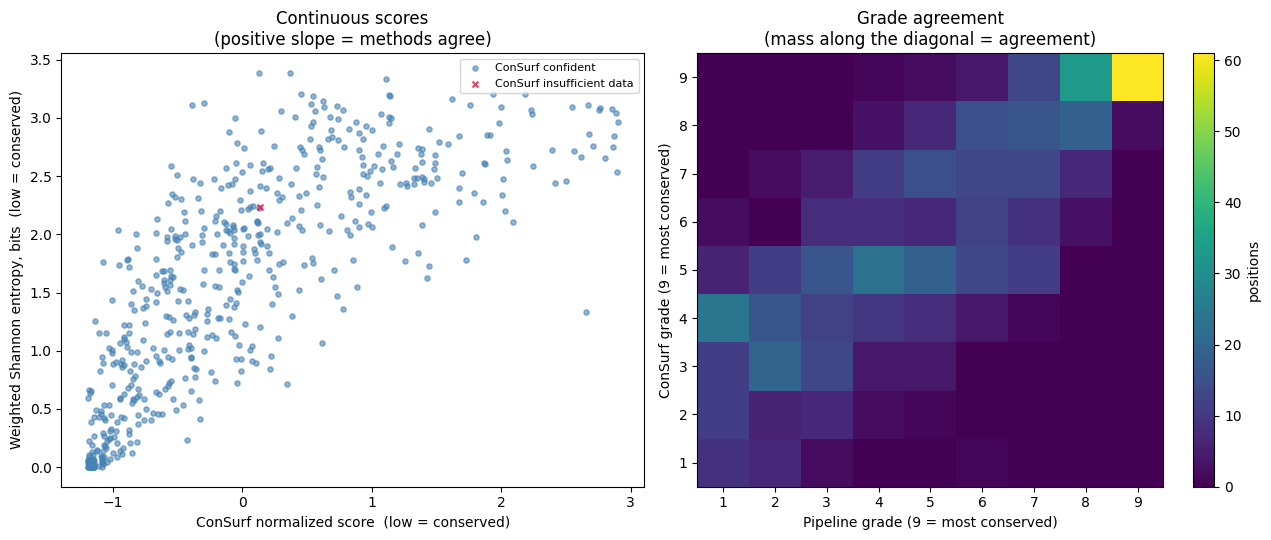

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

confident = comp[~comp["consurf_insufficient_data"]]
flagged = comp[comp["consurf_insufficient_data"]]

axes[0].scatter(confident["consurf_score"], confident["cons_shannon_entropy"],
                s=14, alpha=0.6, color="steelblue", label="ConSurf confident")
axes[0].scatter(flagged["consurf_score"], flagged["cons_shannon_entropy"],
                s=18, alpha=0.8, color="crimson", marker="x", label="ConSurf insufficient data")
axes[0].set_xlabel("ConSurf normalized score  (low = conserved)")
axes[0].set_ylabel("Weighted Shannon entropy, bits  (low = conserved)")
axes[0].set_title("Continuous scores\n(positive slope = methods agree)")
axes[0].legend(fontsize=8)

grade_matrix = pd.crosstab(comp["consurf_grade"], comp["cons_consurf_like_grade"])
im = axes[1].imshow(grade_matrix.values, cmap="viridis", origin="lower", aspect="auto")
axes[1].set_xticks(range(len(grade_matrix.columns)))
axes[1].set_xticklabels(grade_matrix.columns)
axes[1].set_yticks(range(len(grade_matrix.index)))
axes[1].set_yticklabels(grade_matrix.index)
axes[1].set_xlabel("Pipeline grade (9 = most conserved)")
axes[1].set_ylabel("ConSurf grade (9 = most conserved)")
axes[1].set_title("Grade agreement\n(mass along the diagonal = agreement)")
plt.colorbar(im, ax=axes[1], label="positions")

plt.tight_layout()
plt.savefig(fig_dir / "consurf_vs_pipeline.png", dpi=150)
plt.show()

## Deeper check: per-position amino acid frequencies

Stronger than comparing final grades -- matching grades could in principle arise from different underlying distributions. This compares the actual per-position AA composition that feeds each entropy calculation.

In [8]:
# Locate the real header row (the file starts with a prose legend block)
variety_raw = variety_file.read_text(errors="replace").splitlines()
vh_idx = next(i for i, line in enumerate(variety_raw) if line.lstrip().lower().startswith("pos"))
print(f"Variety-table header at line {vh_idx}: {variety_raw[vh_idx][:80]}")

variety_df = pd.read_csv(variety_file, skiprows=vh_idx, sep=None, engine="python")
variety_df.columns = [str(c).strip() for c in variety_df.columns]
variety_df = variety_df[pd.to_numeric(variety_df["pos"], errors="coerce").notna()].copy()
variety_df["pos"] = variety_df["pos"].astype(int)
print(f"Parsed variety table: {variety_df.shape[0]} positions x {variety_df.shape[1]} columns")
variety_df.head(3)

Variety-table header at line 4: pos,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y,OTHER,MAX ACID,ConSurf grade
Parsed variety table: 563 positions x 24 columns


,pos,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y,OTHER,MAX ACID,ConSurf grade
0,1,0.000,0.000,0.0,0.0,7.692,0.0,7.692,15.385,0.000,7.692,53.846,0.000,0.0,0.0,7.692,0.000,0.0,0.0,0.0,0.0,0,M 53.846,5
1,2,8.696,4.348,0.0,0.0,0.000,0.0,0.000,4.348,56.522,0.000,4.348,4.348,0.0,0.0,13.043,4.348,0.0,0.0,0.0,0.0,0,K 56.522,4
2,3,0.000,0.000,0.0,0.0,47.368,0.0,0.000,0.000,26.316,10.526,0.000,0.000,0.0,0.0,15.789,0.000,0.0,0.0,0.0,0.0,0,F 47.368,5


Per-position AA frequency agreement across 11,260 position-AA pairs:
   Spearman rho = +0.817 (p=0.00e+00)
   Pearson  r   = +0.926


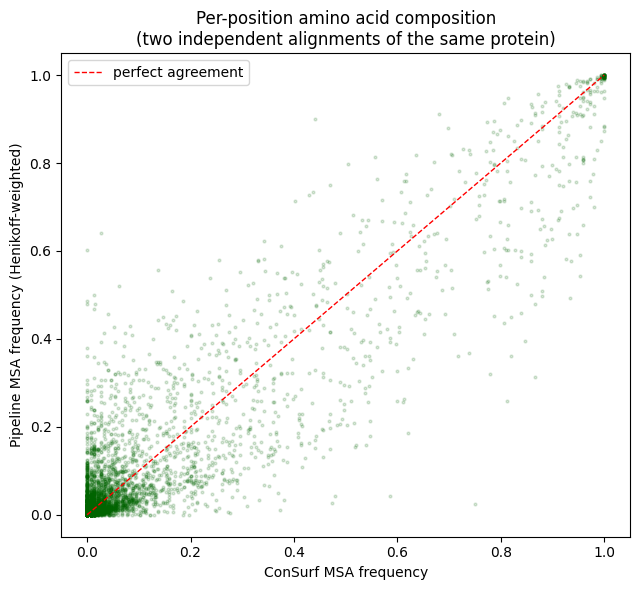

In [9]:
ALL_AAS = list("ACDEFGHIKLMNPQRSTVWY")

freq_rows = []
for _, vrow in variety_df.iterrows():
    pos = vrow["pos"]
    prow = cons_df[cons_df["residue_number"] == pos]
    if prow.empty:
        continue
    prow = prow.iloc[0]
    for aa in ALL_AAS:
        if aa not in vrow.index:
            continue
        freq_rows.append({
            "residue_number": pos,
            "amino_acid": aa,
            "consurf_pct": float(vrow[aa]) / 100.0,
            "pipeline_freq": prow.get(f"cons_freq_{aa}", np.nan),
        })

freq_df = pd.DataFrame(freq_rows).dropna()
rho_freq, p_freq = spearmanr(freq_df["consurf_pct"], freq_df["pipeline_freq"])
r_freq, _ = pearsonr(freq_df["consurf_pct"], freq_df["pipeline_freq"])
print(f"Per-position AA frequency agreement across {len(freq_df):,} position-AA pairs:")
print(f"   Spearman rho = {rho_freq:+.3f} (p={p_freq:.2e})")
print(f"   Pearson  r   = {r_freq:+.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(freq_df["consurf_pct"], freq_df["pipeline_freq"], s=4, alpha=0.15, color="darkgreen")
ax.plot([0, 1], [0, 1], color="red", linestyle="--", lw=1, label="perfect agreement")
ax.set_xlabel("ConSurf MSA frequency")
ax.set_ylabel("Pipeline MSA frequency (Henikoff-weighted)")
ax.set_title("Per-position amino acid composition\n(two independent alignments of the same protein)")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "aa_frequency_agreement.png", dpi=150)
plt.show()

## Where do the two methods disagree most?

Systematic disagreement is more informative than the headline correlation. If large disagreements cluster in ConSurf's insufficient-data positions, that supports the deeper-alignment argument rather than undermining the pipeline.

In [10]:
comp["pipeline_grade_rank"] = comp["cons_consurf_like_grade"].astype(float)
comp["grade_difference"] = comp["pipeline_grade_rank"] - comp["consurf_grade"]

print("Grade difference (pipeline - ConSurf):")
print(comp["grade_difference"].describe())
print(f"\nExact agreement: {(comp['grade_difference'] == 0).sum()} / {comp['grade_difference'].notna().sum()}")
print(f"Within +/-1 grade: {(comp['grade_difference'].abs() <= 1).sum()}")
print(f"Within +/-2 grades: {(comp['grade_difference'].abs() <= 2).sum()}")

print("\nMean |grade difference| by ConSurf confidence:")
print(comp.groupby("consurf_insufficient_data")["grade_difference"].apply(lambda s: s.abs().mean()))

print("\nLargest disagreements:")
worst = comp.reindex(comp["grade_difference"].abs().sort_values(ascending=False).index)
display(worst[["residue_number", "wt_residue", "cons_consurf_like_grade", "consurf_grade",
                "grade_difference", "cons_n_sequences_observed", "consurf_insufficient_data",
                "cons_low_confidence"]].head(15))

Grade difference (pipeline - ConSurf):
count    563.000000
mean      -0.865009
std        1.497174
min       -5.000000
25%       -2.000000
50%       -1.000000
75%        0.000000
max        5.000000
Name: grade_difference, dtype: float64

Exact agreement: 162 / 563
Within +/-1 grade: 354
Within +/-2 grades: 474

Mean |grade difference| by ConSurf confidence:
consurf_insufficient_data
False    1.290036
True     2.000000
Name: grade_difference, dtype: float64

Largest disagreements:


,residue_number,wt_residue,cons_consurf_like_grade,consurf_grade,grade_difference,cons_n_sequences_observed,consurf_insufficient_data,cons_low_confidence
558,559,S,6,1,5.0,278,False,False
35,36,T,1,6,-5.0,307,False,False
67,68,L,1,6,-5.0,316,False,False
176,177,D,2,7,-5.0,322,False,False
216,217,S,2,7,-5.0,321,False,False
302,303,T,4,9,-5.0,321,False,False
304,305,K,5,9,-4.0,321,False,False
367,368,D,3,7,-4.0,322,False,False
415,416,T,1,5,-4.0,315,False,False
418,419,T,4,8,-4.0,322,False,False


In [11]:
comp.to_csv(out_dir / "consurf_comparison.csv", index=False)
freq_df.to_csv(out_dir / "aa_frequency_comparison.csv", index=False)
print(f"Saved comparison tables to {out_dir}")

Saved comparison tables to N:\Jupiter_Projects\rational-enzyme-engineering\results\validation_consurf


In [12]:
import pandas as pd
df = pd.read_csv(r'N:\Jupiter_Projects\rational-enzyme-engineering\results\02_homolog_search/filtered_hits.csv')
print('kept hits:', len(df))
print(df['pident'].describe())
print('\npident value counts (top 15) - are many hits near-identical to each other?')
print(df['pident'].round(0).value_counts().head(15))

kept hits: 350
count    350.000000
mean      58.082857
std       10.112000
min       40.000000
25%       50.625000
50%       56.300000
75%       65.800000
max      100.000000
Name: pident, dtype: float64

pident value counts (top 15) - are many hits near-identical to each other?
pident
52.0    29
74.0    20
58.0    17
51.0    17
49.0    17
50.0    16
59.0    14
55.0    12
47.0    12
75.0    11
60.0    11
54.0    11
53.0    11
72.0    10
65.0    10
Name: count, dtype: int64


In [13]:
import pandas as pd
df = pd.read_csv(r'N:\Jupiter_Projects\rational-enzyme-engineering\results\03_conservation/conservation_scores.csv')
row = df[df.residue_number == 195].iloc[0]
freqs = {c.replace('cons_freq_',''): row[c] for c in df.columns if c.startswith('cons_freq_')}
print('Position 195, wt =', row['wt_residue'], ', entropy =', round(row['cons_shannon_entropy'],3))
print('n_seqs =', row['cons_n_sequences_observed'], ', gap_fraction =', round(row['cons_gap_fraction'],3))
print(sorted([(k, round(v,4)) for k,v in freqs.items() if v > 0.01], key=lambda x: -x[1]))

Position 195, wt = C , entropy = 0.124
n_seqs = 322 , gap_fraction = 0.0
[('C', np.float64(0.9843)), ('unweighted_C', np.float64(0.9783)), ('unweighted_T', np.float64(0.0186)), ('T', np.float64(0.0139))]


In [14]:
# ConSurf's variety table gives WT frequency per position; so does ours.
# If our MSA systematically shows lower WT frequency, our alignment is diluted.
wt_comp = []
for _, vrow in variety_df.iterrows():
    pos = int(vrow["pos"])
    prow = cons_df[cons_df.residue_number == pos]
    if prow.empty:
        continue
    prow = prow.iloc[0]
    wt = prow["wt_residue"]
    if wt not in vrow.index:
        continue
    wt_comp.append({
        "residue_number": pos, "wt_residue": wt,
        "consurf_wt_pct": float(vrow[wt]) / 100.0,
        "pipeline_wt_freq": prow.get(f"cons_freq_{wt}", np.nan),
    })

wt_df = pd.DataFrame(wt_comp).dropna()
wt_df["difference"] = wt_df["pipeline_wt_freq"] - wt_df["consurf_wt_pct"]
print(f"Mean WT frequency -- ConSurf: {wt_df.consurf_wt_pct.mean():.3f}, "
      f"pipeline: {wt_df.pipeline_wt_freq.mean():.3f}")
print(f"Mean difference (pipeline - ConSurf): {wt_df.difference.mean():+.3f}")
print(f"Positions where pipeline WT freq is lower: "
      f"{(wt_df.difference < 0).sum()} / {len(wt_df)}")
display(wt_df.sort_values("difference").head(15))

Mean WT frequency -- ConSurf: 0.589, pipeline: 0.519
Mean difference (pipeline - ConSurf): -0.071
Positions where pipeline WT freq is lower: 391 / 563


,residue_number,wt_residue,consurf_wt_pct,pipeline_wt_freq,difference
562,563,Q,0.75000,0.023758,-0.726242
235,236,Q,0.81208,0.258093,-0.553987
560,561,G,0.86667,0.312826,-0.553844
88,89,G,0.82069,0.361166,-0.459524
418,419,T,0.77852,0.320489,-0.458031
230,231,P,0.84667,0.394821,-0.451849
302,303,T,0.93333,0.493647,-0.439683
99,100,F,0.62069,0.185906,-0.434784
303,304,W,0.95333,0.542634,-0.410696
367,368,D,0.86577,0.479376,-0.386394


In [15]:
from Bio import AlignIO

aln = AlignIO.read(results_dir / "03_conservation" / "alignment.fasta", "fasta")
ref = aln[0]
GAP = {"-", "."}

rows, ref_pos = [], 0
for col in range(aln.get_alignment_length()):
    ref_char = ref.seq[col]
    if ref_char in GAP:
        continue
    ref_pos += 1
    column = [aln[i, col] for i in range(len(aln)) if aln[i, col] not in GAP]
    if not column:
        continue
    counts = pd.Series(column).value_counts(normalize=True)
    rows.append({"residue_number": ref_pos, "wt_residue": ref_char,
                 "unweighted_wt_freq": counts.get(ref_char, 0.0)})

unw_df = pd.DataFrame(rows)
check = wt_df.merge(unw_df[["residue_number", "unweighted_wt_freq"]], on="residue_number")

print(f"Mean WT frequency:")
print(f"  ConSurf (raw counts)     : {check.consurf_wt_pct.mean():.3f}")
print(f"  Pipeline (unweighted)    : {check.unweighted_wt_freq.mean():.3f}")
print(f"  Pipeline (Henikoff-wtd)  : {check.pipeline_wt_freq.mean():.3f}")
display(check.sort_values("difference")[
    ["residue_number", "wt_residue", "consurf_wt_pct",
     "unweighted_wt_freq", "pipeline_wt_freq"]].head(15))

Mean WT frequency:
  ConSurf (raw counts)     : 0.589
  Pipeline (unweighted)    : 0.574
  Pipeline (Henikoff-wtd)  : 0.519


,residue_number,wt_residue,consurf_wt_pct,unweighted_wt_freq,pipeline_wt_freq
562,563,Q,0.75000,0.041322,0.023758
235,236,Q,0.81208,0.735202,0.258093
560,561,G,0.86667,0.260465,0.312826
88,89,G,0.82069,0.704918,0.361166
418,419,T,0.77852,0.677019,0.320489
230,231,P,0.84667,0.723602,0.394821
302,303,T,0.93333,0.890966,0.493647
99,100,F,0.62069,0.503247,0.185906
303,304,W,0.95333,0.853583,0.542634
367,368,D,0.86577,0.770186,0.479376


In [16]:
wt_df_new = cons_df[["residue_number", "wt_residue", "cons_wt_freq_unweighted"]].merge(
    wt_df[["residue_number", "consurf_wt_pct"]], on="residue_number")
wt_df_new["difference"] = wt_df_new["cons_wt_freq_unweighted"] - wt_df_new["consurf_wt_pct"]
print(f"ConSurf: {wt_df_new.consurf_wt_pct.mean():.3f}, "
      f"pipeline unweighted: {wt_df_new.cons_wt_freq_unweighted.mean():.3f}, "
      f"mean diff: {wt_df_new.difference.mean():+.3f}")
print(f"Positions where pipeline is lower: {(wt_df_new.difference < 0).sum()} / {len(wt_df_new)}")

ConSurf: 0.589, pipeline unweighted: 0.574, mean diff: -0.015
Positions where pipeline is lower: 334 / 563


In [17]:
vrow = variety_df[variety_df["pos"] == 559].iloc[0]
print(f"ConSurf n_seqs: {consurf_df[consurf_df.residue_number==559]['consurf_n_sequences'].iloc[0]}")
print({aa: vrow[aa] for aa in "ACDEFGHIKLMNPQRSTVWY" if vrow[aa] > 0.5})
print("ConSurf variety string:", consurf_df[consurf_df.residue_number==559]['consurf_variety'].iloc[0])

ConSurf n_seqs: 91
{'A': np.float64(3.297), 'D': np.float64(4.396), 'E': np.float64(1.099), 'G': np.float64(50.549), 'H': np.float64(2.198), 'I': np.float64(2.198), 'K': np.float64(1.099), 'P': np.float64(2.198), 'R': np.float64(2.198), 'S': np.float64(20.879), 'T': np.float64(7.692), 'V': np.float64(1.099), 'Y': np.float64(1.099)}
ConSurf variety string: G 50%, S 20%, T  7%, D  4%, A  3%, R  2%, H  2%, I  2%, P  2%, Y  1%, K  1%, E  1%, V  1%
